<div align="center">

<h1 style="color:blue; font-weight:bold;">
Analysis and Visualisation: Weather and Road Collisions in Great Britain, 2025
</h1>

</div>

This notebook analyses how daily rainfall and temperature relate to the number and severity of road collisions in Great Britain in 2025, using the integrated datasets from notebook 03:

- **`collisions_weather_2025.csv`**: 101,523 collisions, each with the rainfall and temperature in its 5 km grid cell on the day it happened.
- **`daily_gb_weather_collisions_2025.csv`**: one row per day, with weather across Great Britain and daily collision counts.

Two kinds of question are asked, and each needs a different measure:
- **Frequency:** are there more collisions in wet or cold weather? This needs collisions *per day*, compared with similar days, because traffic varies by weekday and season.
- **Severity:** when a collision happens in wet or cold weather, is it more likely to kill or seriously injure (KSI)? This uses the *share* of collisions that are KSI, which does not depend on how many days of each weather type occurred.

### Step 1: Import Required Libraries



In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Step 2: Load the Integrated Datasets

Load the merged collision table and the daily summary produced in notebook 03, restoring the column types (CSV files store everything as text), and confirm that the two files agree.

In [2]:
merged_dir = Path("../data/merged")

# True/false columns are restored as pandas "boolean", which can hold blanks
# (e.g. police_reported_rain is blank where the police weather record was unknown).
flag_columns = ["police_reported_rain", "police_reported_snow", "surface_wet",
                "surface_ice_snow", "coastal_cell", "ksi"]

collisions = pd.read_csv(
    merged_dir / "collisions_weather_2025.csv",
    dtype={
        "collision_index": str,
        "local_authority_ons_district": str,
        **{column: "boolean" for column in flag_columns},
    },
    parse_dates=["date", "datetime", "rain_day"],
)

daily = pd.read_csv(
    merged_dir / "daily_gb_weather_collisions_2025.csv",
    index_col="day",
    parse_dates=["day"],
)

print("Collisions:", collisions.shape)
print("Daily summary:", daily.shape)
print("Collisions with rainfall:", int(collisions["rainfall_mm"].notna().sum()))
print("Collisions with temperature:", int(collisions["tas_c"].notna().sum()))
print("KSI collisions:", int(collisions["ksi"].sum()),
      f"({100 * collisions['ksi'].mean():.1f}%)")

# The daily table counts every collision with rainfall exactly once.
assert daily["collisions"].sum() == collisions["rainfall_mm"].notna().sum()

Collisions: (101523, 39)
Daily summary: (365, 14)
Collisions with rainfall: 101468
Collisions with temperature: 101523
KSI collisions: 26643 (26.2%)


### Step 2.1: Data Dictionary

Definitions of every variable in the two integrated datasets. Source: **DfT** = DfT road safety data; **HadUK** = Met Office HadUK-Grid; **Derived** = created in notebooks 02–03.

#### Collision table (`collisions_weather_2025.csv`): one row per collision

| Variable | Type | Source | Definition |
|---|---|---|---|
| **Identification and time** | | | |
| `collision_index` | Text | DfT | Unique identifier of the collision; links to the DfT casualty and vehicle tables |
| `date` | Date | DfT | Calendar date of the collision (UK local time) |
| `datetime` | Date-time | Derived | Date and time of the collision (UK local time) |
| `month` | Integer | Derived | Month of the collision (1 = January … 12 = December) |
| `day_of_week` | Integer | DfT | Day of the collision, DfT coding (1 = Sunday … 7 = Saturday) |
| `hour` | Integer | Derived | Hour of the collision, 0–23 (UK local time) |
| **Location** | | | |
| `location_easting_osgr` | Number (m) | DfT | Easting of the collision, British National Grid (EPSG:27700) |
| `location_northing_osgr` | Number (m) | DfT | Northing of the collision, British National Grid (EPSG:27700) |
| `longitude`, `latitude` | Number (°) | DfT | Location of the collision in WGS84 coordinates (for web maps) |
| `country` | Text | Derived | England, Wales or Scotland, from the police force code |
| `police_force` | Code | DfT | Police force that recorded the collision (1–59 England, 60–63 Wales, 99 Police Scotland) |
| `local_authority_ons_district` | Text | DfT | ONS code of the local authority district where the collision occurred (e.g. E06000002) |
| `urban_or_rural_area_label` | Category | DfT | Whether the collision occurred in an urban or rural area |
| **Road** | | | |
| `road_type` | Code | DfT | Type of road: 1 Roundabout, 2 One-way street, 3 Dual carriageway, 6 Single carriageway, 7 Slip road, 9 Unknown |
| `speed_limit` | Integer (mph) | DfT | Speed limit of the road (20, 30, 40, 50, 60 or 70) |
| **Conditions recorded by the police** | | | |
| `light_conditions_label` | Category | DfT | Light at the time of the collision (daylight, or darkness with lights lit, unlit, none or unknown) |
| `weather_conditions_label` | Category | DfT | Weather at the scene as recorded by the police (e.g. fine, raining, snowing, fog), with or without high winds |
| `road_surface_conditions_label` | Category | DfT | Road surface at the scene (dry, wet or damp, snow, frost or ice, flood, oil, mud) |
| `police_reported_rain` | True/False | Derived | True if police recorded rain (with or without high winds); blank if weather was unknown or "Other" |
| `police_reported_snow` | True/False | Derived | True if police recorded snow (with or without high winds); blank if weather was unknown or "Other" |
| `surface_wet` | True/False | Derived | True if the road surface was wet, damp or flooded; blank if unknown |
| `surface_ice_snow` | True/False | Derived | True if the road surface had snow, frost or ice; blank if unknown |
| **Outcome** | | | |
| `collision_severity` | Code | DfT | Severity of the most serious casualty: 1 Fatal, 2 Serious, 3 Slight |
| `collision_severity_label` | Category | DfT | Severity as text (Fatal, Serious, Slight) |
| `ksi` | True/False | Derived | True if the collision was fatal or serious (Killed or Seriously Injured), the standard UK road safety measure |
| `number_of_vehicles` | Integer | DfT | Number of vehicles involved in the collision |
| `number_of_casualties` | Integer | DfT | Number of people injured or killed in the collision |
| `casualties_fatal` | Integer | Derived | Number of casualties who died (within 30 days, DfT definition) |
| `casualties_serious` | Integer | Derived | Number of casualties seriously injured |
| `casualties_slight` | Integer | Derived | Number of casualties slightly injured |
| `casualties_pedestrian` | Integer | Derived | Number of casualties who were pedestrians |
| **Weather (from HadUK-Grid)** | | | |
| `rainfall_mm` | Number (mm) | HadUK | Total rainfall in the collision's 5 km grid cell over its rain day (09:00–09:00 UTC); blank for 55 collisions whose rain day falls in 2024 |
| `tas_c` | Number (°C) | HadUK | Daily mean air temperature in the collision's cell, the average of the day's maximum and minimum (midnight–midnight UTC) |
| `rain_day` | Date | Derived | The HadUK-Grid rain day the collision belongs to (its UTC time minus 9 hours) |
| `weather_match` | Category | Derived | How weather was assigned: "own cell", or "nearest cell" (adjacent cell within 10 km, used where the collision's cell has no data) |
| `weather_cell_row`, `weather_cell_col` | Integer | Derived | Row and column of the weather grid cell used for the collision |
| `coastal_cell` | True/False | Derived | True if the weather cell is a partly-land coastal cell whose centre lies outside the UK boundary |

#### Daily table (`daily_gb_weather_collisions_2025.csv`): one row per day

| Variable | Type | Source | Definition |
|---|---|---|---|
| `day` | Date | Derived | Day of 2025; for collision counts, the rain day (09:00 to 09:00 UTC) |
| `gb_mean_rainfall_mm` | Number (mm) | HadUK | Average rainfall across all Great Britain grid cells |
| `gb_share_rain_day_pct` | Number (%) | HadUK | Percentage of Great Britain with at least 0.2 mm of rain (a rain day) |
| `gb_share_wet_day_pct` | Number (%) | HadUK | Percentage of Great Britain with at least 1 mm of rain (a wet day) |
| `gb_mean_tas_c` | Number (°C) | HadUK | Average daily mean temperature across Great Britain |
| `gb_share_below_3c_pct` | Number (%) | HadUK | Percentage of Great Britain with a daily mean temperature below 3 °C (near-freezing) |
| `collisions` | Integer | Derived | Number of collisions on the day |
| `ksi_collisions` | Integer | Derived | Number of fatal or serious collisions on the day |
| `fatal_collisions` | Integer | Derived | Number of fatal collisions on the day |
| `casualties` | Integer | Derived | Number of casualties on the day |
| `ksi_casualties` | Integer | Derived | Number of people killed or seriously injured on the day |
| `collisions_rain_day_in_cell` | Integer | Derived | Number of collisions whose own grid cell had a rain day (≥ 0.2 mm) |
| `day_of_week` | Text | Derived | Name of the day (Monday … Sunday); note this differs from the numeric DfT coding in the collision table |
| `month` | Integer | Derived | Month (1 = January … 12 = December) |
| `weekend` | True/False | Derived | True for Saturday and Sunday |

---

### Step 3: Collisions per Day in Wet Weather

**Question: are there more collisions on days when it rains across Great Britain?**

Comparing raw collision counts between wet and dry days would mislead, because traffic, and so collisions, varies strongly by day of the week and season. For example, a wet Sunday in December may have fewer collisions than a dry Friday in June simply because fewer people are driving.

We therefore compare each day with a **baseline**: the average number of collisions on the **same weekday in the same month**, leaving out the day itself so that it is not compared with its own value. A day with 300 collisions against a baseline of 280 is +7.1%.

**Bank holidays** (England and Wales dates for 2025) are excluded, because their traffic patterns differ from an ordinary day of the same weekday. Scottish bank holidays differ slightly and are not excluded; this is a minor limitation, since Scotland accounts for about 4% of collisions.

Days are then grouped by how much of Great Britain had a **wet day** (at least 1 mm of rain), from mostly dry (0–20% of the country) to widespread rain (80–100%). For each group we show the average difference from baseline with a 95% confidence interval: the range within which the true average is likely to lie, given the number of days.

Bank holidays flagged: 8
Days compared: 357
Mean difference from baseline (all days): 0.56%

Collisions per day relative to the same weekday and month,
by share of Great Britain with at least 1 mm of rain:
          days  mean_relative_pct  ci95
wet_band                               
0–20%      140               1.75  2.89
20–40%      70              -0.84  3.66
40–60%      46               1.32  4.31
60–80%      52              -2.92  3.69
80–100%     49               2.14  3.25


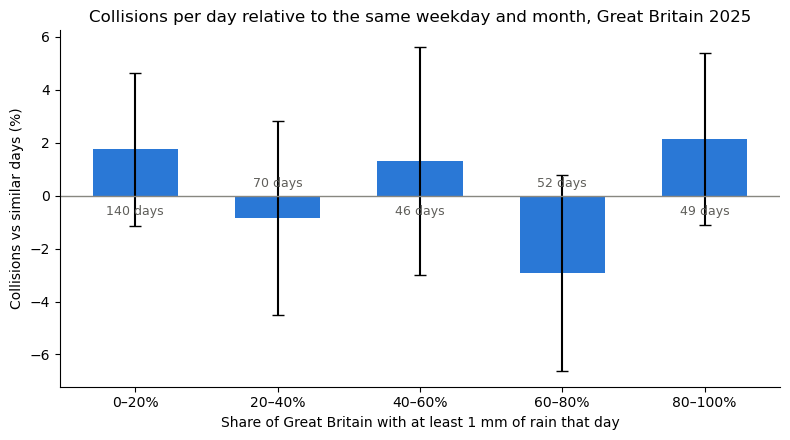

In [3]:
# --- 1. Flag bank holidays (England and Wales, 2025) ----------------------------

# Bank holidays have holiday traffic patterns, so they are not compared with
# ordinary days of the same weekday.
bank_holidays = pd.to_datetime([
    "2025-01-01",  # New Year's Day
    "2025-04-18",  # Good Friday
    "2025-04-21",  # Easter Monday
    "2025-05-05",  # Early May bank holiday
    "2025-05-26",  # Spring bank holiday
    "2025-08-25",  # Summer bank holiday
    "2025-12-25",  # Christmas Day
    "2025-12-26",  # Boxing Day
])
daily["bank_holiday"] = daily.index.isin(bank_holidays)
print("Bank holidays flagged:", int(daily["bank_holiday"].sum()))

# --- 2. Baseline: same weekday, same month, excluding the day itself ------------

ordinary = daily[~daily["bank_holiday"]].copy()

# Leave-one-out mean: (group total - this day) / (group size - 1), so a day
# is never compared with itself.
group = ordinary.groupby(["month", "day_of_week"])["collisions"]
group_sum = group.transform("sum")
group_size = group.transform("size")
ordinary["baseline"] = (group_sum - ordinary["collisions"]) / (group_size - 1)

# Percentage difference from the baseline (+10 = 10% more collisions than usual).
ordinary["relative_pct"] = 100 * (ordinary["collisions"] / ordinary["baseline"] - 1)

print("Days compared:", len(ordinary))
print(f"Mean difference from baseline (all days): {ordinary['relative_pct'].mean():.2f}%")

# --- 3. Group days by how much of Great Britain was wet -----------------------------

band_edges = [0, 20, 40, 60, 80, 100.001]   # the last edge includes exactly 100%
band_labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
ordinary["wet_band"] = pd.cut(
    ordinary["gb_share_wet_day_pct"], bins=band_edges, labels=band_labels, right=False
)

summary = ordinary.groupby("wet_band", observed=False)["relative_pct"].agg(["count", "mean", "std"])

# 95% confidence interval for each group's mean: 1.96 standard errors.
summary["ci95"] = 1.96 * summary["std"] / np.sqrt(summary["count"])
summary = summary.rename(columns={"count": "days", "mean": "mean_relative_pct"})

print("\nCollisions per day relative to the same weekday and month,")
print("by share of Great Britain with at least 1 mm of rain:")
print(summary[["days", "mean_relative_pct", "ci95"]].round(2))

# --- 4. Chart ---------------------------------------------------------------------

# Save charts to a figures folder for the report and development log.
figure_dir = Path("../figures")
figure_dir.mkdir(exist_ok=True)

plot_data = summary.dropna(subset=["mean_relative_pct"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(plot_data.index.astype(str), plot_data["mean_relative_pct"],
       yerr=plot_data["ci95"], capsize=4, color="#2a78d6", width=0.6)

# Zero line = a typical day for that weekday and month.
ax.axhline(0, color="#888780", linewidth=1)

# Show how many days each bar is based on, so small groups are visible.
for i, (days, value) in enumerate(zip(plot_data["days"], plot_data["mean_relative_pct"])):
    ax.annotate(f"{int(days)} days", (i, 0), xytext=(0, -14 if value >= 0 else 6),
                textcoords="offset points", ha="center", fontsize=9, color="#5F5E5A")

ax.set_xlabel("Share of Great Britain with at least 1 mm of rain that day")
ax.set_ylabel("Collisions vs similar days (%)")
ax.set_title("Collisions per day relative to the same weekday and month, Great Britain 2025")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(figure_dir / "step3_collisions_by_wet_share.png", dpi=200)
plt.show()

#### Interpretation of Step 3

| Share of GB with ≥ 1 mm rain | Days | Collisions vs similar days | 95% CI |
|---|---:|---:|---:|
| 0–20% | 140 | +1.75% | ±2.89 |
| 20–40% | 70 | -0.84% | ±3.66 |
| 40–60% | 46 | +1.32% | ±4.31 |
| 60–80% | 52 | -2.92% | ±3.69 |
| 80–100% | 49 | +2.14% | ±3.25 |

At the level of whole days across Great Britain, there is **no detectable relationship** between how widespread the rain was and the number of collisions. Every group is within about 3% of a typical day for its weekday and month, every confidence interval includes zero, and there is no consistent trend.

This does not show that rain has no effect. A national daily figure mixes wet and dry places: on a day when half the country is wet, collisions in the dry half are counted alongside those in the wet half. Any local effect is diluted. Step 3.2 therefore compares each collision with the rainfall in its own 5 km cell.

This chart was abandoned for the final visualisation: its day-count labels overlap the bars and error bars, and its five bars of different heights suggest differences that the confidence intervals show are not meaningful.

### Step 3.2: Collisions Compared with the Same Places on Similar Days

**Question: when it rains in a particular place, do more collisions happen there than usual?**

Each 5 km cell has a usual number of collisions per day: busy urban cells have many, remote rural cells very few. Rainfall also differs by place: the west and the uplands are wetter. A direct comparison of wet and dry cell-days would mostly compare wet, quiet rural areas with drier, busy towns.

To avoid this, we use an **observed versus expected** comparison:
1. For every Great Britain cell, calculate its **usual collisions per day** over 2025.
2. Adjust this for the **month and weekday**, using how busy each month–weekday combination is across Great Britain (for example, Fridays in November are busier than Sundays in August).
3. For every cell on every day (about 3.6 million cell-days), this gives the **expected** number of collisions if the weather made no difference.
4. Group the cell-days by their rainfall and compare the collisions that actually happened (**observed**) with the **expected** number.

If rain makes no difference, observed and expected are equal in every rainfall band (0% difference). If rain increases collisions, wet bands show more than expected.

Rainfall bands use the British thresholds from notebook 03: below 0.2 mm (dry), 0.2–1 mm (a rain day), then 1–5, 5–10 and 10+ mm. The 95% confidence interval comes from the observed count, treating collisions as random events (a Poisson count).

The weather file is reloaded here, and the Great Britain mask from notebook 03 Step 3 is rebuilt using the same boundary and method.

Great Britain cells: 9779
Cell-days: 3569335

Collisions observed vs expected for the same cells, months and weekdays:
                  cell_days  share_of_cell_days_pct  observed  expected  obs_vs_exp_pct  ci95_pct
rainfall_in_cell                                                                                 
Dry (<0.2 mm)       1728422                    48.4     58378     57878             0.9       0.8
0.2–1 mm             488210                    13.7     13020     13498            -3.5       1.7
1–5 mm               712862                    20.0     17385     17566            -1.0       1.5
5–10 mm              318181                     8.9      7244      7251            -0.1       2.3
10+ mm               321660                     9.0      5441      5275             3.1       2.7


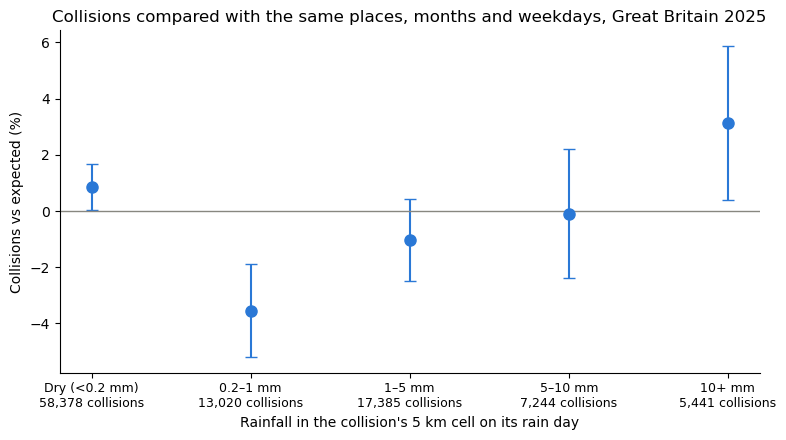

In [4]:
import xarray as xr
import geopandas as gpd
import pyogrio
import shapely

# --- 1. Reload the weather grid and rebuild the Great Britain mask ----------------

weather = xr.open_dataset(Path("../data/weather/processed/uk_weather_2025_masked.nc"))
analysis_mask = weather["analysis_mask"].astype(bool).values
grid_x = weather["projection_x_coordinate"].values
grid_y = weather["projection_y_coordinate"].values
half_cell = float(grid_x[1] - grid_x[0]) / 2

# Same boundary and cell-overlap test as notebook 03, Step 3.
pyogrio.set_gdal_config_options({"OGR_GEOJSON_MAX_OBJ_SIZE": "0"})
uk_boundary = gpd.read_file(Path("../data/boundaries/Countries_December_2025_Boundaries_UK_BFC_-2912039989678096674.geojson"))
gb_geometry = uk_boundary[uk_boundary["CTRY25NM"] != "Northern Ireland"].geometry.union_all()
shapely.prepare(gb_geometry)

x_mesh, y_mesh = np.meshgrid(grid_x, grid_y)
cell_boxes = shapely.box(x_mesh - half_cell, y_mesh - half_cell, x_mesh + half_cell, y_mesh + half_cell)
gb_mask = analysis_mask & shapely.intersects(gb_geometry, cell_boxes)
print("Great Britain cells:", int(gb_mask.sum()))   # should match notebook 03: 9,779

# Rainfall as (rain day, cell) for Great Britain cells only; float32 saves memory.
rain_days = pd.DatetimeIndex(weather.time.values).normalize()
rainfall = weather["rainfall"].values[:, gb_mask].astype("float32")
weather.close()

# Number each GB cell 0..n-1, so a collision's row/column can be turned into a cell number.
gb_rows, gb_cols = np.nonzero(gb_mask)
cell_id = np.full(gb_mask.shape, -1)
cell_id[gb_rows, gb_cols] = np.arange(len(gb_rows))
n_days, n_cells = rainfall.shape
print("Cell-days:", n_days * n_cells)

# --- 2. Rainfall band of every cell-day ---

band_edges = [0, 0.2, 1, 5, 10, np.inf]
band_labels = ["Dry (<0.2 mm)", "0.2–1 mm", "1–5 mm", "5–10 mm", "10+ mm"]
cell_day_band = np.digitize(rainfall, band_edges[1:-1])   # 0 = dry ... 4 = 10+ mm

# --- 3. Place each collision on its cell and rain day ---

matched = collisions[collisions["rainfall_mm"].notna() & (collisions["weather_cell_row"] >= 0)].copy()
matched["cell"] = cell_id[matched["weather_cell_row"], matched["weather_cell_col"]]
matched["t"] = (
    pd.Series(np.arange(n_days), index=rain_days)
    .reindex(matched["rain_day"].dt.normalize())
    .to_numpy()
)
assert (matched["cell"] >= 0).all() and matched["t"].notna().all()
matched["t"] = matched["t"].astype(int)
matched["band"] = cell_day_band[matched["t"], matched["cell"]]

# --- 4. Expected collisions for every cell-day ---

# Usual collisions per day in each cell over 2025.
cell_mean = np.bincount(matched["cell"], minlength=n_cells) / n_days

# How busy each day is for its month and weekday, relative to the average day.
calendar = pd.DataFrame({"day": rain_days})
calendar["collisions"] = np.bincount(matched["t"], minlength=n_days)
calendar["month"] = calendar["day"].dt.month
calendar["weekday"] = calendar["day"].dt.dayofweek
calendar["factor"] = (
    calendar.groupby(["month", "weekday"])["collisions"].transform("mean")
    / calendar["collisions"].mean()
)
factor = calendar["factor"].to_numpy()

# Expected = cell's usual rate x day's month-weekday factor, summed by rainfall band.
# Looping over the 365 days keeps memory low (one day of cells at a time).
expected = np.zeros(len(band_labels))
cell_days = np.zeros(len(band_labels), dtype=np.int64)
for t in range(n_days):
    expected += factor[t] * np.bincount(cell_day_band[t], weights=cell_mean, minlength=len(band_labels))
    cell_days += np.bincount(cell_day_band[t], minlength=len(band_labels))

observed = np.bincount(matched["band"], minlength=len(band_labels))

# Scale so total expected equals total observed; the comparison is then
# purely about how collisions are distributed across rainfall bands.
expected *= observed.sum() / expected.sum()

# --- 5. Results ---

result = pd.DataFrame({
    "cell_days": cell_days,
    "share_of_cell_days_pct": 100 * cell_days / cell_days.sum(),
    "observed": observed,
    "expected": expected.round(0).astype(int),
}, index=pd.Index(band_labels, name="rainfall_in_cell"))
result["obs_vs_exp_pct"] = 100 * (observed / expected - 1)
result["ci95_pct"] = 100 * 1.96 * np.sqrt(observed) / expected   # Poisson interval

pd.set_option("display.width", 120)
print("\nCollisions observed vs expected for the same cells, months and weekdays:")
print(result.round(1))

# --- 6. Chart ---

# A dot with an interval, rather than a bar: the quantity is a difference
# from zero, and dots avoid implying that bar length (area) carries meaning.
fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(band_labels))
ax.errorbar(positions, result["obs_vs_exp_pct"], yerr=result["ci95_pct"],
            fmt="o", color="#2a78d6", markersize=8, capsize=4, linewidth=1.5)
ax.axhline(0, color="#888780", linewidth=1)

# Collision counts go under the x labels, so they cannot collide with the data.
ax.set_xticks(positions)
ax.set_xticklabels([f"{label}\n{n:,} collisions" for label, n in zip(band_labels, observed)], fontsize=9)
ax.set_xlabel("Rainfall in the collision's 5 km cell on its rain day")
ax.set_ylabel("Collisions vs expected (%)")
ax.set_title("Collisions compared with the same places, months and weekdays, Great Britain 2025")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(figure_dir / "step3_2_collisions_vs_expected_by_cell_rainfall.png", dpi=200)
plt.show()

#### Interpretation of Step 3.2

| Rainfall in cell | Share of cell-days | Observed | Expected | Difference | 95% CI |
|---|---:|---:|---:|---:|---:|
| Dry (< 0.2 mm) | 48.4% | 58,378 | 57,878 | +0.9% | ±0.8 |
| 0.2–1 mm | 13.7% | 13,020 | 13,498 | -3.5% | ±1.7 |
| 1–5 mm | 20.0% | 17,385 | 17,566 | -1.0% | ±1.5 |
| 5–10 mm | 8.9% | 7,244 | 7,251 | -0.1% | ±2.3 |
| 10+ mm | 9.0% | 5,441 | 5,275 | +3.1% | ±2.7 |

Comparing each place with itself on similar days shows that **rainfall changes the number of collisions only slightly**, and not in a simple "more rain, more collisions" pattern:
- **Heavy rain (10 mm or more)** is the only band with clearly more collisions than expected: +3.1%, with a confidence interval that stays above zero.
- **Light rain (0.2–1 mm)** has clearly fewer collisions than expected (-3.5%). One possible explanation is that drivers slow down or travel less in drizzle while roads are not yet much more hazardous, but this data cannot test that.
- **Moderate rain (1–10 mm)** shows no detectable difference.

The comparison also shows why the place-by-place approach was needed: 10+ mm days make up 9.0% of cell-days but only 5.4% of collisions, because heavy rain falls mostly in the wet, lightly populated west and uplands. A direct comparison would have suggested heavy rain *reduces* collisions.

**Limitations:** the expected numbers adjust for place, month and weekday, but not for traffic volume on each day. If people drive less in heavy rain, the true risk per vehicle-mile is higher than +3.1% suggests. Rainfall is also a 24-hour total, so it does not show whether rain was falling at the moment of the collision.

### Step 4: Collision Severity in Wet Weather

**Question: when a collision happens in rain, is it more likely to kill or seriously injure (KSI)?**

Severity uses the **share of collisions that are KSI** in each rainfall band. As a share, it does not depend on how many days of each kind of weather occurred.

A direct comparison would still mislead, because the type of road strongly affects severity and is linked to rainfall. Rural roads with high speed limits produce more serious collisions and are mostly in the wetter west and uplands. Darkness also increases severity and is more common in the wetter winter months.

We therefore compare the observed number of KSI collisions in each band with the number **expected for the same road types**. Collisions are grouped by:
- urban or rural area,
- speed limit (20–30, 40–50, 60–70 mph),
- daylight or darkness.

Each collision's expected chance of being KSI is the KSI share of its group across all weather. Summing these chances over a band gives the expected KSI count if rain made no difference to severity once road type is accounted for. The 95% confidence interval treats each collision's outcome as a yes/no event with that expected chance.

Road surface condition is deliberately **not** used for grouping. A wet surface is one of the ways rain could affect severity, so adjusting for it would hide the effect being measured.

Road-type groups: 14

KSI share by rainfall in the collision's cell:
               collisions  ksi_observed  ksi_share_pct  expected_share_pct  obs_vs_exp_pct  ci95_pct
band_label                                                                                          
Dry (<0.2 mm)       58378         15524           26.6                26.0             2.1       1.4
0.2–1 mm            13020          3327           25.6                26.3            -2.8       2.9
1–5 mm              17385          4512           26.0                26.4            -1.8       2.5
5–10 mm              7244          1868           25.8                26.7            -3.4       3.8
10+ mm               5441          1394           25.6                27.1            -5.4       4.3


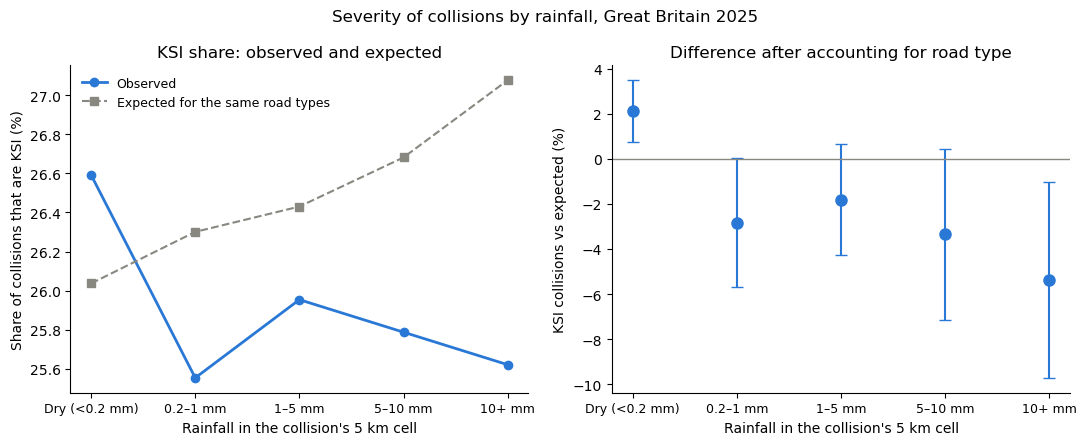

In [5]:
# Start from the collisions placed on cell-days in Step 3.2.
severity = matched.copy()
severity["ksi_flag"] = severity["ksi"].astype(bool)
severity["band_label"] = pd.Categorical.from_codes(severity["band"], categories=band_labels)

# --- 1. Road-type groups ---
# Darkness covers all four darkness categories (lights lit, unlit, none, unknown).
severity["darkness"] = severity["light_conditions_label"].str.startswith("Darkness")

# Speed limits grouped into urban, intermediate and high-speed roads.
severity["speed_group"] = pd.cut(
    severity["speed_limit"], bins=[0, 30, 50, 70],
    labels=["20–30 mph", "40–50 mph", "60–70 mph"],
)

strata = ["urban_or_rural_area_label", "speed_group", "darkness"]

# Each collision's expected chance of KSI = KSI share of its group, across all weather.
severity["stratum_ksi_rate"] = (
    severity.groupby(strata, observed=True)["ksi_flag"].transform("mean")
)
print("Road-type groups:", severity.groupby(strata, observed=True).ngroups)
assert severity["stratum_ksi_rate"].notna().all()

# --- 2. Observed and expected KSI by rainfall band ---

by_band = severity.groupby("band_label", observed=False).agg(
    collisions=("ksi_flag", "size"),
    ksi_observed=("ksi_flag", "sum"),
    ksi_expected=("stratum_ksi_rate", "sum"),
    # Variance of a sum of yes/no outcomes with chances p: sum of p(1 - p).
    variance=("stratum_ksi_rate", lambda p: (p * (1 - p)).sum()),
)

by_band["ksi_share_pct"] = 100 * by_band["ksi_observed"] / by_band["collisions"]
by_band["expected_share_pct"] = 100 * by_band["ksi_expected"] / by_band["collisions"]
by_band["obs_vs_exp_pct"] = 100 * (by_band["ksi_observed"] / by_band["ksi_expected"] - 1)
by_band["ci95_pct"] = 100 * 1.96 * np.sqrt(by_band["variance"]) / by_band["ksi_expected"]

print("\nKSI share by rainfall in the collision's cell:")
print(by_band[["collisions", "ksi_observed", "ksi_share_pct", "expected_share_pct",
               "obs_vs_exp_pct", "ci95_pct"]].round(1))

# --- 3. Chart: raw shares beside the adjusted difference ---

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
positions = np.arange(len(band_labels))

# Left: observed KSI share against what road type alone would predict.
axes[0].plot(positions, by_band["ksi_share_pct"], marker="o", color="#2a78d6",
             linewidth=2, label="Observed")
axes[0].plot(positions, by_band["expected_share_pct"], marker="s", color="#888780",
             linewidth=1.5, linestyle="--", label="Expected for the same road types")
axes[0].set_ylabel("Share of collisions that are KSI (%)")
axes[0].set_title("KSI share: observed and expected")
axes[0].legend(frameon=False, fontsize=9)

# Right: the difference that remains after accounting for road type.
axes[1].errorbar(positions, by_band["obs_vs_exp_pct"], yerr=by_band["ci95_pct"],
                 fmt="o", color="#2a78d6", markersize=8, capsize=4, linewidth=1.5)
axes[1].axhline(0, color="#888780", linewidth=1)
axes[1].set_ylabel("KSI collisions vs expected (%)")
axes[1].set_title("Difference after accounting for road type")

for ax in axes:
    ax.set_xticks(positions)
    ax.set_xticklabels(band_labels, fontsize=9)
    ax.set_xlabel("Rainfall in the collision's 5 km cell")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Severity of collisions by rainfall, Great Britain 2025")
plt.tight_layout()
fig.savefig(figure_dir / "step4_ksi_share_by_cell_rainfall.png", dpi=200)
plt.show()

#### Interpretation of Step 4

| Rainfall in cell | Collisions | KSI share | Expected for road types | KSI vs expected | 95% CI |
|---|---:|---:|---:|---:|---:|
| Dry (< 0.2 mm) | 58,378 | 26.6% | 26.0% | +2.1% | ±1.4 |
| 0.2–1 mm | 13,020 | 25.6% | 26.3% | -2.8% | ±2.9 |
| 1–5 mm | 17,385 | 26.0% | 26.4% | -1.8% | ±2.5 |
| 5–10 mm | 7,244 | 25.8% | 26.7% | -3.4% | ±3.8 |
| 10+ mm | 5,441 | 25.6% | 27.1% | -5.4% | ±4.3 |

**Collisions in wet weather are slightly less likely to be fatal or serious than expected.** The expected KSI share rises with rainfall (26.0% to 27.1%), because wet collisions happen more often on rural, high-speed and dark roads where collisions are usually more severe. The observed share does not rise: it is 25.6% in heavy rain. After accounting for road type, collisions in heavy rain are 5.4% less likely to be KSI than expected, while dry-day collisions are 2.1% more likely. Both intervals exclude zero. The light and moderate rain bands point the same way, but their intervals include zero.

Combined with Step 3.2, heavy rain is associated with **slightly more collisions that are, on average, less severe**. A likely explanation is that drivers reduce speed in heavy rain, lowering the energy of the collisions that do occur, but this data cannot confirm driver behaviour.

The two panels also show how the choice of comparison changes the message. The raw KSI shares (left) suggest only a small dip in wet weather; comparing with what road type predicts (right) shows a clearer reduction in severity, because wet-weather collisions happen on roads where severity is normally higher.

The left panel was abandoned for the final visualisation: its y-axis is truncated (25.6% to 27.0%), which exaggerates a one-point difference, and it shows no uncertainty.

### Step 5: Collisions and Temperature

**Question: do cold conditions, especially near freezing, change how many collisions happen or how serious they are?**

The two methods from Steps 3.2 and 4 are applied to temperature, with the same adjustments:
- **Frequency:** collisions observed versus expected for the same 5 km cell, month and weekday.
- **Severity:** KSI collisions observed versus expected for the same road types (urban or rural, speed limit, daylight or darkness).

Temperature is the HadUK-Grid daily mean in the collision's cell, the average of the day's maximum and minimum. Its day runs midnight to midnight UTC, so each collision uses its temperature day from notebook 03, not its rain day.

Bands focus on the cold end, where ice is possible: below 0 °C, 0–3 °C (near-freezing), 3–10 °C, 10–15 °C, 15–20 °C and 20 °C or more.

Both methods are written as functions here, so they can be reused for other weather measures without repeating code.

Temperature bands agree with tas_c from notebook 03: True

Frequency: collisions vs expected for the same cells, months and weekdays
            cell_days  collisions  expected  obs_vs_exp_pct  ci95_pct
band                                                                 
Below 0 °C      78667         866       873            -0.8       6.6
0–3 °C         263688        4585      4857            -5.6       2.7
3–10 °C       1390119       33162     32971             0.6       1.1
10–15 °C      1118903       31582     31871            -0.9       1.1
15–20 °C       622851       24482     24576            -0.4       1.2
20 °C+          95107        6791      6320             7.5       2.6

Severity: KSI collisions vs expected for the same road types
            collisions  ksi_observed  ksi_share_pct  obs_vs_exp_pct  ci95_pct
temp_band                                                                    
Below 0 °C         866           208           24.0           -11.7      10.8
0–3 °C     

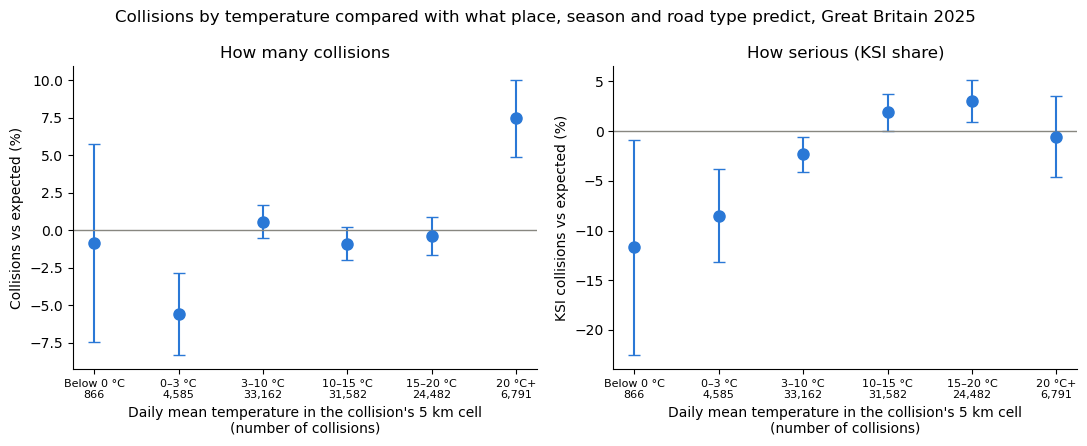

In [6]:
# --- 1. Reusable versions of the Step 3.2 and Step 4 methods ------------------------

def frequency_vs_expected(day_cell_band, collision_t, collision_cell, labels, days):
    """Collisions observed vs expected for the same cell, month and weekday, by band.

    day_cell_band: (days, cells) array of band numbers for every cell-day.
    collision_t, collision_cell: day index and cell number of every collision.
    """
    n_days, n_cells = day_cell_band.shape

    # Usual collisions per day in each cell, and how busy each month-weekday is.
    usual = np.bincount(collision_cell, minlength=n_cells) / n_days
    cal = pd.DataFrame({"day": days, "collisions": np.bincount(collision_t, minlength=n_days)})
    cal["factor"] = (
        cal.groupby([cal["day"].dt.month, cal["day"].dt.dayofweek])["collisions"].transform("mean")
        / cal["collisions"].mean()
    )

    # Expected collisions and cell-days in each band, one day at a time.
    expected = np.zeros(len(labels))
    cell_days = np.zeros(len(labels), dtype=np.int64)
    for t in range(n_days):
        expected += cal["factor"].iat[t] * np.bincount(day_cell_band[t], weights=usual, minlength=len(labels))
        cell_days += np.bincount(day_cell_band[t], minlength=len(labels))

    observed = np.bincount(day_cell_band[collision_t, collision_cell], minlength=len(labels))
    expected *= observed.sum() / expected.sum()   # compare distributions, not totals

    out = pd.DataFrame(
        {"cell_days": cell_days, "collisions": observed, "expected": expected.round(0).astype(int)},
        index=pd.Index(labels, name="band"),
    )
    out["obs_vs_exp_pct"] = 100 * (observed / expected - 1)
    out["ci95_pct"] = 100 * 1.96 * np.sqrt(observed) / expected   # Poisson interval
    return out


def severity_vs_expected(df, band_column, labels):
    """KSI collisions observed vs expected for the same road types, by band (Step 4 method)."""
    g = df.groupby(band_column, observed=False).agg(
        collisions=("ksi_flag", "size"),
        ksi_observed=("ksi_flag", "sum"),
        ksi_expected=("stratum_ksi_rate", "sum"),
        variance=("stratum_ksi_rate", lambda p: (p * (1 - p)).sum()),
    )
    g["ksi_share_pct"] = 100 * g["ksi_observed"] / g["collisions"]
    g["obs_vs_exp_pct"] = 100 * (g["ksi_observed"] / g["ksi_expected"] - 1)
    g["ci95_pct"] = 100 * 1.96 * np.sqrt(g["variance"]) / g["ksi_expected"]
    return g


# --- 2. Temperature for every Great Britain cell-day ----
weather = xr.open_dataset(Path("../data/weather/processed/uk_weather_2025_masked.nc"))
tas = weather["tas"].values[:, gb_mask].astype("float32")
tas_days = pd.DatetimeIndex(weather.time.values).normalize()
weather.close()

temp_edges = [-np.inf, 0, 3, 10, 15, 20, np.inf]
temp_labels = ["Below 0 °C", "0–3 °C", "3–10 °C", "10–15 °C", "15–20 °C", "20 °C+"]
temp_band = np.digitize(tas, temp_edges[1:-1])

# --- 3. Each collision's temperature day (midnight-midnight UTC, as in notebook 03) ---

local = severity["datetime"].dt.tz_localize("Europe/London", ambiguous=False, nonexistent="shift_forward")
tas_day = local.dt.tz_convert("UTC").dt.tz_localize(None).dt.normalize()
severity["t_tas"] = pd.Series(np.arange(len(tas_days)), index=tas_days).reindex(tas_day).to_numpy()
assert severity["t_tas"].notna().all()
severity["t_tas"] = severity["t_tas"].astype(int)
severity["temp_band"] = pd.Categorical.from_codes(
    temp_band[severity["t_tas"], severity["cell"]], categories=temp_labels
)

# Check: the bands match the tas_c values attached in notebook 03.
check = np.digitize(severity["tas_c"].to_numpy(), temp_edges[1:-1])
print("Temperature bands agree with tas_c from notebook 03:",
      bool((check == severity["temp_band"].cat.codes.to_numpy()).all()))

# --- 4. Frequency and severity by temperature ---

temp_frequency = frequency_vs_expected(
    temp_band, severity["t_tas"].to_numpy(), severity["cell"].to_numpy(), temp_labels, tas_days
)
temp_severity = severity_vs_expected(severity, "temp_band", temp_labels)

print("\nFrequency: collisions vs expected for the same cells, months and weekdays")
print(temp_frequency.round(1))
print("\nSeverity: KSI collisions vs expected for the same road types")
print(temp_severity[["collisions", "ksi_observed", "ksi_share_pct", "obs_vs_exp_pct", "ci95_pct"]].round(1))

# --- 5. Chart: frequency and severity side by side, on the same kind of scale ---------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
positions = np.arange(len(temp_labels))

for ax, table, title, ylabel in [
    (axes[0], temp_frequency, "How many collisions", "Collisions vs expected (%)"),
    (axes[1], temp_severity, "How serious (KSI share)", "KSI collisions vs expected (%)"),
]:
    ax.errorbar(positions, table["obs_vs_exp_pct"], yerr=table["ci95_pct"],
                fmt="o", color="#2a78d6", markersize=8, capsize=4, linewidth=1.5)
    ax.axhline(0, color="#888780", linewidth=1)
    ax.set_xticks(positions)
    ax.set_xticklabels([f"{label}\n{n:,}" for label, n in zip(temp_labels, table["collisions"])], fontsize=8)
    ax.set_xlabel("Daily mean temperature in the collision's 5 km cell\n(number of collisions)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Collisions by temperature compared with what place, season and road type predict, Great Britain 2025")
plt.tight_layout()
fig.savefig(figure_dir / "step5_collisions_by_temperature.png", dpi=200)
plt.show()

#### Interpretation of Step 5

| Temperature | Collisions | Frequency vs expected | 95% CI | KSI vs expected | 95% CI |
|---|---:|---:|---:|---:|---:|
| Below 0 °C | 866 | -0.8% | ±6.6 | -11.7% | ±10.8 |
| 0–3 °C | 4,585 | -5.6% | ±2.7 | -8.5% | ±4.7 |
| 3–10 °C | 33,162 | +0.6% | ±1.1 | -2.3% | ±1.8 |
| 10–15 °C | 31,582 | -0.9% | ±1.1 | +1.9% | ±1.8 |
| 15–20 °C | 24,482 | -0.4% | ±1.2 | +3.0% | ±2.1 |
| 20 °C+ | 6,791 | +7.5% | ±2.6 | -0.6% | ±4.1 |

**Frequency.** Near-freezing days (0–3 °C) have 5.6% fewer collisions than expected for the same places, months and weekdays, and hot days (20 °C or more) have 7.5% more. Below 0 °C there are too few collisions (866) for a clear result. Hot days may bring more leisure travel, and people may travel less or more carefully when roads may be icy, but traffic volume is not in the data.

**Severity.** The share of collisions that are KSI rises steadily with temperature. Collisions on near-freezing days are 8.5% less likely to be KSI than expected for the same road types, and below 0 °C 11.7% less likely; both intervals stay below zero. In mild conditions (10–20 °C) collisions are slightly more severe than expected.

**Combined with Steps 3.2 and 4,** the 2025 data shows a consistent pattern: in adverse weather (heavy rain or cold), collisions are less often fatal or serious, while the more severe collisions occur in mild, dry conditions. Possible explanations include lower speeds in poor conditions and more motorcyclists and cyclists on warm, dry days, but these would need traffic and vehicle data to confirm.

The panels use different y-axis ranges because they measure different outcomes; values should be compared within a panel, not across them.

### Step 6: Does Rain Matter More in Darkness or on Fast Roads?

**Question: is the effect of rain different at night, or on high-speed roads?**

Rain may be more dangerous in combination with other conditions, such as darkness, which reduces visibility, or fast roads, where stopping distances are longer. We repeat the frequency (Step 3.2) and severity (Step 4) comparisons separately for four groups of collisions:
- daylight and darkness,
- urban roads (20–30 mph) and fast roads (60–70 mph).

To keep enough collisions in each group, rainfall is reduced to three bands: dry (below 0.2 mm), light to moderate (0.2–10 mm) and heavy (10 mm or more).

The results are shown as **small multiples**: a grid of identical small charts, one column per group, with the same y-axis across each row so groups can be compared directly. Frequency is in the top row and severity in the bottom row.

Within each group, frequency is compared with that group's own usual pattern. For example, darkness collisions in a cell are compared with that cell's usual number of darkness collisions.

                                           collisions  freq_vs_exp_pct  freq_ci95  ksi_vs_exp_pct  ksi_ci95
subgroup                rainfall                                                                           
Daylight                Dry                     44297              3.0        1.0             2.6       1.6
                        Light to moderate       25303             -4.3        1.2            -4.0       2.1
                        Heavy (10+ mm)           3223             -4.3        3.3            -4.3       5.8
Darkness                Dry                     14081             -5.3        1.6             0.9       2.6
                        Light to moderate       12346              3.8        1.8             0.2       2.8
                        Heavy (10+ mm)           2218             17.1        4.9            -6.8       6.5
Urban roads (20–30 mph) Dry                     40541              1.2        1.0             1.2       1.7
                        Ligh

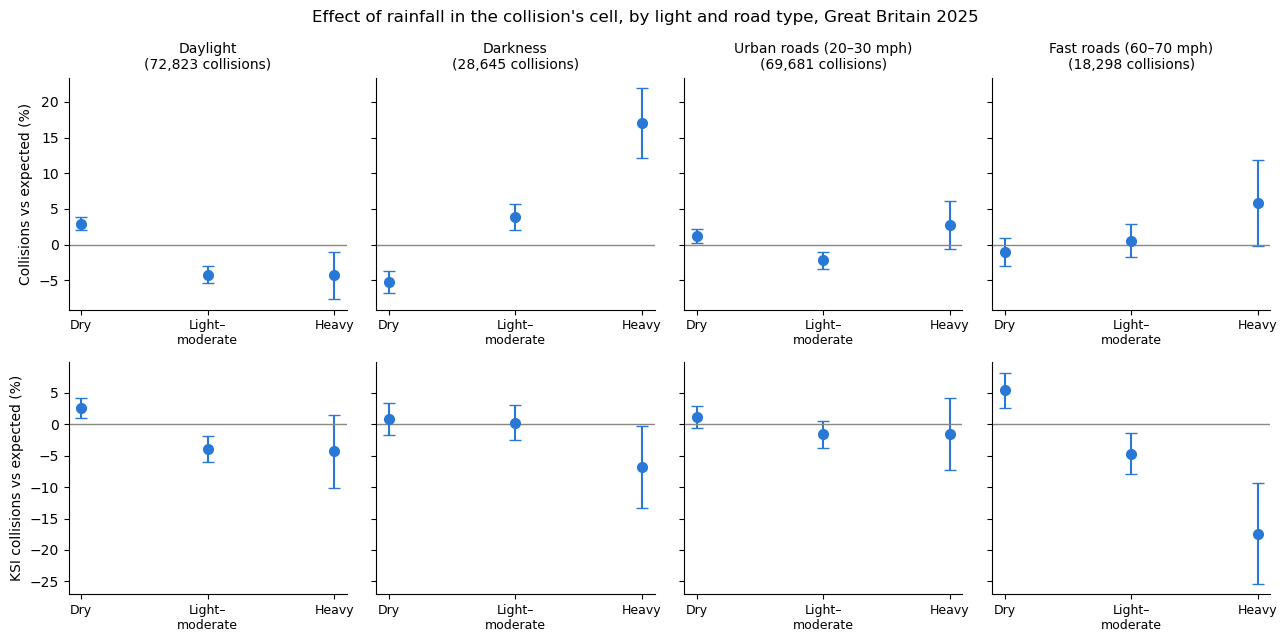

In [7]:
# --- 1. Three rainfall bands for every cell-day and every collision -------------------

rain3_labels = ["Dry", "Light to moderate", "Heavy (10+ mm)"]

# From the five Step 3.2 bands: 0 = dry, 1-3 = light to moderate, 4 = heavy.
rain3_grid = np.select([cell_day_band == 0, cell_day_band == 4], [0, 2], default=1)
severity["rain3"] = pd.Categorical.from_codes(
    rain3_grid[severity["t"], severity["cell"]], categories=rain3_labels
)

# --- 2. Run both comparisons within each group ---------------------------------------

subgroups = {
    "Daylight": ~severity["darkness"],
    "Darkness": severity["darkness"],
    "Urban roads (20–30 mph)": severity["speed_group"] == "20–30 mph",
    "Fast roads (60–70 mph)": severity["speed_group"] == "60–70 mph",
}

rows = []
for name, mask in subgroups.items():
    sub = severity[mask]
    # Frequency uses the group's own usual rate in each cell (inside the function).
    freq = frequency_vs_expected(rain3_grid, sub["t"].to_numpy(), sub["cell"].to_numpy(),
                                 rain3_labels, rain_days)
    sev = severity_vs_expected(sub, "rain3", rain3_labels)
    for label in rain3_labels:
        rows.append({
            "subgroup": name,
            "rainfall": label,
            "collisions": int(freq.loc[label, "collisions"]),
            "freq_vs_exp_pct": freq.loc[label, "obs_vs_exp_pct"],
            "freq_ci95": freq.loc[label, "ci95_pct"],
            "ksi_vs_exp_pct": sev.loc[label, "obs_vs_exp_pct"],
            "ksi_ci95": sev.loc[label, "ci95_pct"],
        })

interaction = pd.DataFrame(rows).set_index(["subgroup", "rainfall"])
print(interaction.round(1))

# --- 3. Small multiples: one column per group, same y-axis along each row ----------------

fig, axes = plt.subplots(2, len(subgroups), figsize=(13, 6.5), sharey="row")
positions = np.arange(len(rain3_labels))

for j, name in enumerate(subgroups):
    part = interaction.loc[name]
    for i, (col, ci, ylabel) in enumerate([
        ("freq_vs_exp_pct", "freq_ci95", "Collisions vs expected (%)"),
        ("ksi_vs_exp_pct", "ksi_ci95", "KSI collisions vs expected (%)"),
    ]):
        ax = axes[i, j]
        ax.errorbar(positions, part[col], yerr=part[ci], fmt="o", color="#2a78d6",
                    markersize=7, capsize=4, linewidth=1.5)
        ax.axhline(0, color="#888780", linewidth=1)
        ax.set_xticks(positions)
        ax.set_xticklabels(["Dry", "Light–\nmoderate", "Heavy"], fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
        if i == 0:
            ax.set_title(f"{name}\n({part['collisions'].sum():,} collisions)", fontsize=10)
        if j == 0:
            ax.set_ylabel(ylabel)

fig.suptitle("Effect of rainfall in the collision's cell, by light and road type, Great Britain 2025")
plt.tight_layout()
fig.savefig(figure_dir / "step6_rain_by_light_and_road.png", dpi=200)
plt.show()

#### Interpretation of Step 6

| Group | Rainfall | Collisions | Frequency vs expected | KSI vs expected |
|---|---|---:|---:|---:|
| Daylight | Dry | 44,297 | +3.0% (±1.0) | +2.6% (±1.6) |
| | Light to moderate | 25,303 | -4.3% (±1.2) | -4.0% (±2.1) |
| | Heavy | 3,223 | -4.3% (±3.3) | -4.3% (±5.8) |
| Darkness | Dry | 14,081 | -5.3% (±1.6) | +0.9% (±2.6) |
| | Light to moderate | 12,346 | +3.8% (±1.8) | +0.2% (±2.8) |
| | Heavy | 2,218 | **+17.1% (±4.9)** | -6.8% (±6.5) |
| Urban roads (20–30 mph) | Dry | 40,541 | +1.2% (±1.0) | +1.2% (±1.7) |
| | Light to moderate | 25,641 | -2.2% (±1.2) | -1.6% (±2.2) |
| | Heavy | 3,499 | +2.7% (±3.4) | -1.5% (±5.8) |
| Fast roads (60–70 mph) | Dry | 10,004 | -1.0% (±1.9) | **+5.4% (±2.8)** |
| | Light to moderate | 7,090 | +0.5% (±2.3) | -4.6% (±3.3) |
| | Heavy | 1,204 | +5.8% (±6.0) | **-17.4% (±8.0)** |

**Rain and darkness.** The effect of rain on collision numbers depends strongly on light. In darkness, heavy rain brings 17.1% more collisions than expected for the same places, months and weekdays, the largest effect found in this analysis. In daylight, heavy rain brings 4.3% fewer. Reduced visibility, glare from wet roads and headlights, and spray are plausible reasons rain is more hazardous after dark. The overall heavy-rain increase in Step 3.2 (+3.1%) is therefore an average of a large night-time increase and a small daytime decrease.

**Rain and fast roads.** On 60–70 mph roads, collisions in heavy rain are 17.4% less likely to be KSI than expected, while collisions on dry fast roads are 5.4% more likely. This is consistent with drivers reducing speed on fast roads in poor conditions, though speeds are not recorded in the data.

**Urban roads** show little change with rain in either frequency or severity.

**Caution:** twelve comparisons are made here, so one or two intervals could exclude zero by chance. The two highlighted heavy-rain results are large relative to their uncertainty and consistent with the earlier steps, so they are unlikely to be chance findings.

### Step 7: Where Are Wet Days Most Hazardous?

**Question: does the effect of rain on collision numbers differ across Great Britain?**

For each 5 km cell, the collisions on its **wet days** (at least 1 mm) are compared with the number expected from that cell's usual rate, adjusted for month and weekday, using the Step 3.2 method. Most single cells have too few collisions for a reliable result, so cells are grouped into **25 km blocks** (5 × 5 cells).

The map uses a **diverging colour scale**: red for more wet-day collisions than expected, blue for fewer, and white for no difference. Blocks expecting fewer than 30 wet-day collisions are left grey, because a ratio based on a handful of collisions mostly reflects chance. Values beyond ±30% share the end colour.

Even with this threshold, a block expecting 30 collisions has a 95% uncertainty of roughly ±35%, so individual blocks should be read with care. The map shows the spread of local differences more reliably than it identifies specific hotspots.

Collisions on wet cell-days (>= 1 mm): 30070
Overall wet-day collisions vs expected: -0.1%
25 km blocks with enough expected wet-day collisions: 194
Block differences: median -0.2%, 10th percentile -13.5%, 90th percentile +11.3%


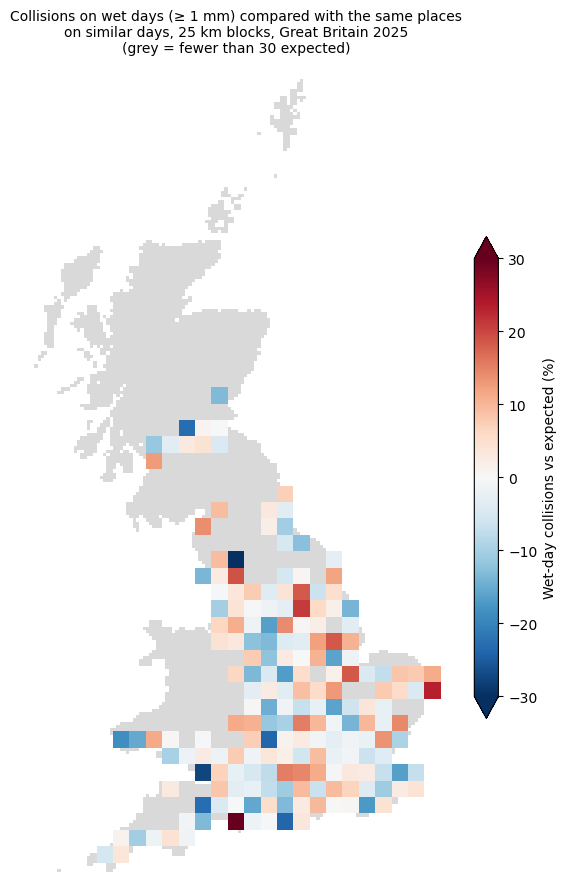

In [8]:
from matplotlib.colors import TwoSlopeNorm

# --- 1. Expected and observed wet-day collisions for every cell -------------------

wet_threshold = 1.0   # Met Office "days of rain" threshold (mm)

# Usual collisions per day in each cell, and how busy each month-weekday is (Step 3.2).
usual = np.bincount(severity["cell"], minlength=n_cells) / n_days
cal = pd.DataFrame({"day": rain_days, "collisions": np.bincount(severity["t"], minlength=n_days)})
cal["factor"] = (
    cal.groupby([cal["day"].dt.month, cal["day"].dt.dayofweek])["collisions"].transform("mean")
    / cal["collisions"].mean()
)
factor_days = cal["factor"].to_numpy()

# Expected = usual rate x sum of the day factors over the cell's wet days.
wet = rainfall >= wet_threshold                      # (days, cells) True on wet cell-days
expected_all = usual * factor_days.sum()
expected_wet = usual * (factor_days[:, None] * wet).sum(axis=0)
expected_wet *= len(severity) / expected_all.sum()    # same scaling as Step 3.2

# Observed collisions that happened on a wet day in their cell.
is_wet_collision = wet[severity["t"].to_numpy(), severity["cell"].to_numpy()]
observed_wet = np.bincount(severity.loc[is_wet_collision, "cell"], minlength=n_cells)

print("Collisions on wet cell-days (>= 1 mm):", int(observed_wet.sum()))
print(f"Overall wet-day collisions vs expected: {100 * (observed_wet.sum() / expected_wet.sum() - 1):+.1f}%")

# --- 2. Group cells into 25 km blocks ---------------------------------------------

block = 5   # 5 x 5 cells of 5 km = 25 km
block_row = gb_rows // block
block_col = gb_cols // block
n_brows = int(np.ceil(len(grid_y) / block))
n_bcols = int(np.ceil(len(grid_x) / block))

obs_block = np.zeros((n_brows, n_bcols))
exp_block = np.zeros((n_brows, n_bcols))
np.add.at(obs_block, (block_row, block_col), observed_wet)   # sum cells into blocks
np.add.at(exp_block, (block_row, block_col), expected_wet)

# Only blocks expecting at least 30 wet-day collisions get a value.
min_expected = 30
ratio_pct = np.where(
    exp_block >= min_expected,
    100 * (obs_block / np.where(exp_block > 0, exp_block, 1) - 1),
    np.nan,
)
reliable = ~np.isnan(ratio_pct)
print("25 km blocks with enough expected wet-day collisions:", int(reliable.sum()))
print(f"Block differences: median {np.nanmedian(ratio_pct):+.1f}%, "
      f"10th percentile {np.nanpercentile(ratio_pct, 10):+.1f}%, "
      f"90th percentile {np.nanpercentile(ratio_pct, 90):+.1f}%")

# --- 3. Map --------------------------------------------------------------------------

# Block edges in British National Grid metres, so the map is to scale.
block_size = (grid_x[1] - grid_x[0]) * block
x_edges = grid_x[0] - (grid_x[1] - grid_x[0]) / 2 + block_size * np.arange(n_bcols + 1)
y_edges = grid_y[0] - (grid_y[1] - grid_y[0]) / 2 + block_size * np.arange(n_brows + 1)

fig, ax = plt.subplots(figsize=(7, 9))

# Light grey land underneath, so blocks without a value still show Great Britain.
land = np.where(gb_mask, 1.0, np.nan)
ax.pcolormesh(grid_x, grid_y, land, cmap="Greys", vmin=0, vmax=4, shading="nearest")

# Diverging scale centred on zero: red = more than expected, blue = fewer.
limit = 30
mesh = ax.pcolormesh(
    x_edges, y_edges, np.clip(ratio_pct, -limit, limit), cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit), shading="flat",
)
cbar = fig.colorbar(mesh, ax=ax, shrink=0.6, extend="both")
cbar.set_label("Wet-day collisions vs expected (%)")

ax.set_aspect("equal")
ax.set_xlim(x_edges[block_col.min()], x_edges[block_col.max() + 1])
ax.set_ylim(y_edges[block_row.min()], y_edges[block_row.max() + 1])
ax.set_axis_off()
ax.set_title(
    f"Collisions on wet days (≥ {wet_threshold:g} mm) compared with the same places\n"
    f"on similar days, 25 km blocks, Great Britain 2025\n(grey = fewer than {min_expected} expected)",
    fontsize=10,
)
plt.tight_layout()
fig.savefig(figure_dir / "step7_wet_day_collisions_map.png", dpi=200)
plt.show()

#### Is the variation between blocks real?

If wet weather affected some areas more than others, the block differences would be larger than chance alone produces. We test this in two ways:
- **z-scores:** for each block, (observed − expected) / √expected. If differences are pure chance, about 5% of blocks fall beyond ±1.96 and the z-scores have a standard deviation of about 1.
- **Simulation:** 1,000 versions of the map are generated in which every block's count is random around its expected value (a Poisson draw). The spread of these chance-only maps is compared with the real one.

Each cell's usual rate is estimated from the same collisions being tested, which pulls observed and expected slightly closer together. The test is therefore slightly conservative: chance-only variation is, if anything, overstated.

In [9]:
# Blocks with enough expected collisions (from Step 7).
o = obs_block[reliable]
e = exp_block[reliable]

# z-score: how many standard errors each block is from its expected count.
z = (o - e) / np.sqrt(e)
print("Blocks tested:", len(z))
print(f"Blocks beyond ±1.96 (expected by chance alone: about 5%): {100 * (np.abs(z) > 1.96).mean():.1f}%")
print(f"Spread of z-scores: standard deviation {z.std():.2f} (pure chance gives about 1.0)")

# Simulate 1,000 maps where every block varies only by chance around its expected count.
rng = np.random.default_rng(2025)            # fixed seed so the result is reproducible
simulated = rng.poisson(e, size=(1000, len(e)))
sim_pct = 100 * (simulated / e - 1)

print(f"Observed 10th–90th percentile of block differences: "
      f"{np.percentile(ratio_pct[reliable], 10):+.1f}% to {np.percentile(ratio_pct[reliable], 90):+.1f}%")
print(f"Same range if every difference were pure chance: "
      f"{np.percentile(sim_pct, 10):+.1f}% to {np.percentile(sim_pct, 90):+.1f}%")

Blocks tested: 194
Blocks beyond ±1.96 (expected by chance alone: about 5%): 2.1%
Spread of z-scores: standard deviation 0.86 (pure chance gives about 1.0)
Observed 10th–90th percentile of block differences: -13.5% to +11.3%
Same range if every difference were pure chance: -14.7% to +14.6%


#### Interpretation of Step 7

| Check | Real map | Chance alone |
|---|---:|---:|
| Blocks beyond ±1.96 | 2.1% of 194 | about 5% |
| Standard deviation of z-scores | 0.86 | about 1.0 |
| 10th–90th percentile of block differences | -13.5% to +11.3% | -14.7% to +14.6% |

The variation between 25 km blocks is **no larger than chance alone would produce**. The strong reds and blues on the map are random fluctuation in small counts, not real local differences. Overall, wet-day collisions match expectation (-0.1%), and **there is no evidence that some parts of Great Britain are more affected by wet weather than others**. The figures are slightly below the chance-only values, as expected from the conservative bias described above.

This map was abandoned for the final visualisation. Its colours mostly show noise, and a diverging red–blue scale would invite a decision-maker to treat random blocks as hotspots. Most of Scotland and Wales could not be shown at all. The dashboard map will instead show stable quantities, such as collision counts and KSI share, with weather as a filter.

### Step 7.1: Time of Day on Wet and Dry Days

**Question: on wet days, do collisions shift towards particular times of day?**

Step 6 found that heavy rain increases collisions mainly in darkness. Here we check whether wet days change *when* collisions happen. Collisions on wet days (at least 1 mm in their cell) and dry days (below 0.2 mm) are each spread across the 24 hours as a percentage, so the two can be compared even though there are more dry-day collisions.

Rainfall is a 24-hour total, so this compares collisions on wet days with collisions on dry days. It does not show whether it was raining at the hour of each collision.

Share of collisions in darkness:
day_type
Dry (<0.2 mm)         24.1
Wet (1 mm or more)    35.1
Name: light_conditions_label, dtype: float64

Share of collisions by period of the day (%):
day_type              Dry (<0.2 mm)  Wet (1 mm or more)
Night (00–05)                   5.3                 5.7
Morning peak (06–09)           16.5                17.8
Daytime (10–15)                36.6                34.5
Evening peak (16–19)           29.7                29.6
Late evening (20–23)           12.0                12.6


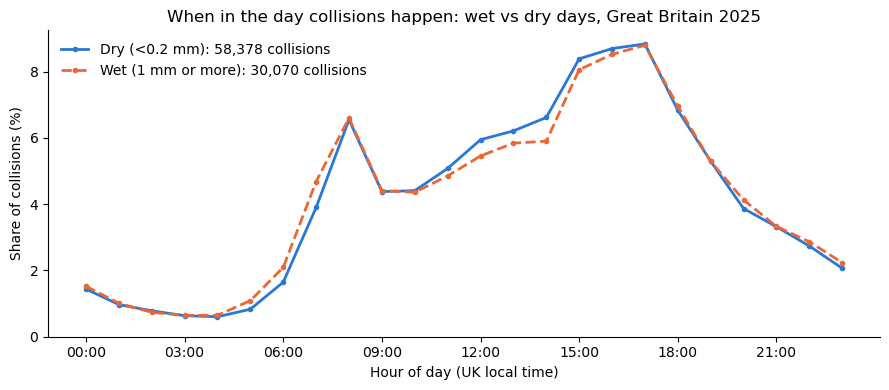

In [12]:
# Wet and dry days only; light-rain days (0.2–1 mm) are left out for a clear contrast.
timing = collisions[collisions["rainfall_mm"].notna()].copy()
timing["day_type"] = np.select(
    [timing["rainfall_mm"] < 0.2, timing["rainfall_mm"] >= 1],
    ["Dry (<0.2 mm)", "Wet (1 mm or more)"],
    default="Light (0.2–1 mm)",
)
timing = timing[timing["day_type"] != "Light (0.2–1 mm)"]

# Percentage of each day type's collisions in each hour.
hour_share = (
    timing.groupby("day_type")["hour"].value_counts(normalize=True)
    .unstack(0).reindex(range(24), fill_value=0) * 100
)

# Share of collisions in darkness on wet and dry days.
darkness_share = timing.groupby("day_type")["light_conditions_label"].apply(
    lambda s: 100 * s.str.startswith("Darkness").mean()
)
print("Share of collisions in darkness:")
print(darkness_share.round(1))

# Summarise the 24 hours into five periods of the day.
periods = pd.cut(
    hour_share.index, bins=[-1, 5, 9, 15, 19, 23],
    labels=["Night (00–05)", "Morning peak (06–09)", "Daytime (10–15)",
            "Evening peak (16–19)", "Late evening (20–23)"],
)
print("\nShare of collisions by period of the day (%):")
print(hour_share.groupby(periods, observed=True).sum().round(1))

# Line chart: the same view as the dashboard's hour profile.
fig, ax = plt.subplots(figsize=(9, 4))
for label, style in [("Dry (<0.2 mm)", dict(color="#2a78d6", linestyle="-")),
                     ("Wet (1 mm or more)", dict(color="#eb6834", linestyle="--"))]:
    ax.plot(hour_share.index, hour_share[label], marker="o", markersize=3, linewidth=2,
            label=f"{label}: {int((timing['day_type'] == label).sum()):,} collisions", **style)
ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)])
ax.set_xlabel("Hour of day (UK local time)")
ax.set_ylabel("Share of collisions (%)")
ax.set_ylim(bottom=0)
ax.set_title("When in the day collisions happen: wet vs dry days, Great Britain 2025")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(figure_dir / "step7_1_hour_of_day_wet_vs_dry.png", dpi=200)
plt.show()

#### Interpretation of Step 7.1

| Period of the day | Dry days | Wet days |
|---|---:|---:|
| Night (00–05) | 5.3% | 5.7% |
| Morning peak (06–09) | 16.5% | 17.8% |
| Daytime (10–15) | 36.6% | 34.5% |
| Evening peak (16–19) | 29.7% | 29.6% |
| Late evening (20–23) | 12.0% | 12.6% |
| **In darkness** | **24.1%** | **35.1%** |

**Wet days change the time of day of collisions only slightly.** The hourly profiles almost overlap: wet days have a slightly larger share in the early morning (05:00–08:00) and a slightly smaller share in the middle of the day. The early-morning shift may partly reflect the rain-day definition. A collision at 07:00 belongs to the rain day that ended at 09:00, which covers the preceding night, when the roads would still be wet.

**The larger share of wet-day collisions in darkness (35.1% against 24.1%) is mainly seasonal.** Wet days are more frequent in autumn and winter, when the evening peak falls after dark, so this comparison mixes the effect of rain with the effect of the time of year. It should not be read as evidence that rain causes more night-time collisions. The seasonally adjusted comparison in Step 6, which compares darkness collisions with the same places, months and weekdays, is the valid measure: heavy rain brings 17.1% more collisions in darkness than expected.

Together, Steps 6 and 7.1 indicate that rain does not change when people travel. Rather, rain makes the hours that are already dark more hazardous.

### Summary of Findings

Collisions in Great Britain in 2025 were compared with the weather in their own 5 km cell on the same day, against what place, season, weekday and road type would predict.

| # | Finding | Evidence |
|---|---|---|
| 1 | **Rain changes the number of collisions only slightly overall.** Heavy rain (10+ mm) brings 3.1% more; light rain (0.2–1 mm) 3.5% fewer. | Step 3.2 |
| 2 | **Heavy rain after dark is the main exception: 17.1% more collisions than expected.** In daylight, heavy rain brings 4.3% fewer. | Step 6 |
| 3 | **Collisions in bad weather are less severe.** Heavy-rain collisions are 5.4% less likely to be KSI, and near-freezing ones 8.5% less likely. | Steps 4 and 5 |
| 4 | **The biggest severity reduction is on fast roads:** collisions on 60–70 mph roads in heavy rain are 17.4% less likely to be KSI, while dry fast roads are 5.4% more likely. | Step 6 |
| 5 | **The more serious collisions happen in mild, dry conditions.** Severity rises with temperature, and hot days (20 °C+) bring 7.5% more collisions. | Steps 4 and 5 |
| 6 | **No regional pattern:** wet weather affects collision numbers similarly across Great Britain. | Step 7 |
| 7 | **Wet days do not change when collisions happen**: the hourly profiles of wet and dry days almost overlap. The higher share of wet-day collisions in darkness (35% vs 24%) is mainly seasonal, so the night-time effect is measured by the adjusted comparison in finding 2. | Step 7.1 |

**Implication for saving lives:** road safety effort aimed only at bad-weather days would miss where the risk is. Heavy rain at night calls for targeted warnings, since collisions rise sharply then, but the most serious collisions happen on dry, mild days, especially on fast roads, when drivers are not slowed by the conditions.

**Main limitations:** no traffic volume data (fewer people may drive in bad weather, so risk per mile could be higher than these figures suggest); rainfall and temperature are daily values, not conditions at the moment of the collision; and explanations such as lower speeds in rain are plausible but not measured.

### Step 8: Export Inputs for the Dashboard

The dashboard recalculates the frequency comparisons (Steps 3.2, 5 and 6) for whatever filters are selected. Each selection must be compared with its own month–weekday pattern, as in Step 6. For example, darkness collisions are concentrated in winter, so they must not be compared with the seasonal pattern of all collisions.

For every Great Britain cell, we therefore save **how many days it spent in each weather band in each of the 84 month–weekday combinations** (12 months × 7 weekdays). The dashboard combines these counts with the selected collisions' own usual rates and month–weekday pattern to reproduce the notebook's expected counts. A check confirms that the dashboard method gives the same result as Step 6 for darkness collisions.

In [13]:
def month_weekday(days):
    """Month-weekday group of each day: 0..83 (12 months x 7 weekdays)."""
    days = pd.DatetimeIndex(days)
    return ((days.month - 1) * 7 + days.dayofweek).to_numpy()


def exposure_counts(day_cell_band, days, n_bands):
    """Days each cell spent in each band, by month-weekday group: (cells, bands, 84)."""
    n_days, n_cells = day_cell_band.shape
    mw = month_weekday(days)
    counts = np.zeros((n_cells, n_bands, 84), dtype=np.uint16)
    cells = np.arange(n_cells)
    for t in range(n_days):
        np.add.at(counts, (cells, day_cell_band[t], mw[t]), 1)
    return counts


rain_counts = exposure_counts(cell_day_band, rain_days, len(band_labels))
temp_counts = exposure_counts(temp_band, tas_days, len(temp_labels))


def expected_from_counts(day_index, cell_index, counts, days):
    """Expected collisions per band using the selection's own usual rates and month-weekday pattern."""
    n_days = len(days)
    usual = np.bincount(cell_index, minlength=counts.shape[0]) / n_days
    daily = np.bincount(day_index, minlength=n_days)
    group_mean = pd.Series(daily).groupby(month_weekday(days)).mean().reindex(range(84)).fillna(0)
    factor = group_mean.to_numpy() / daily.mean()
    return np.einsum("c,cbm->bm", usual, counts.astype(float)) @ factor


# Check: the dashboard method reproduces Step 6 for darkness collisions.
dark = severity[severity["darkness"]]
rain3_counts = np.stack(
    [rain_counts[:, 0], rain_counts[:, 1:4].sum(axis=1), rain_counts[:, 4]], axis=1
)
e = expected_from_counts(dark["t"].to_numpy(), dark["cell"].to_numpy(), rain3_counts, rain_days)
o = np.bincount(rain3_grid[dark["t"], dark["cell"]], minlength=3)
e *= o.sum() / e.sum()
check_dark = 100 * (o / e - 1)
print("Darkness, dashboard method:", np.round(check_dark, 1))
print("Darkness, Step 6 table:    ", interaction.loc["Darkness", "freq_vs_exp_pct"].round(1).to_numpy())
assert np.allclose(check_dark, interaction.loc["Darkness", "freq_vs_exp_pct"].to_numpy(), atol=0.05)

# Save to the dashboard folder (compressed NumPy file, about 2 MB).
dashboard_dir = Path("../dashboard")
dashboard_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(dashboard_dir / "exposure_counts.npz",
                    rain=rain_counts, temp=temp_counts, rows=gb_rows, cols=gb_cols)
print("Saved", dashboard_dir / "exposure_counts.npz")

Darkness, dashboard method: [-5.3  3.8 17.1]
Darkness, Step 6 table:     [-5.3  3.8 17.1]
Saved ..\dashboard\exposure_counts.npz


### From Analysis to Dashboard

The Streamlit dashboard (`dashboard/app.py`) presents these findings interactively, using the same methods:

| Dashboard tab | Visualisation | Notebook source |
|---|---|---|
| Weather effects | Map of collisions or KSI share | New view: counts and KSI share replace the ratio map abandoned in Step 7 |
| Weather effects | How many collisions by rainfall or temperature | Steps 3.2 and 5 |
| Weather effects | How serious by rainfall or temperature | Steps 4 and 5 |
| Light and road type | Daylight vs darkness; urban vs fast roads | Step 6 |
| When | Hour-of-day profile | Step 7.1 |
| When | Weekly collisions and rainfall | Daily table, notebook 03 Step 7 |
| Data check | Police weather vs HadUK rainfall; temperature by road surface | Notebook 03 Step 6 |

Unlike the notebook, the dashboard recalculates the comparisons for whatever filters are selected, using the exposure weights exported in Step 8.